<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Magnetic_Force_Microscopy_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

Minimizing magnets...
Creating MFM images...


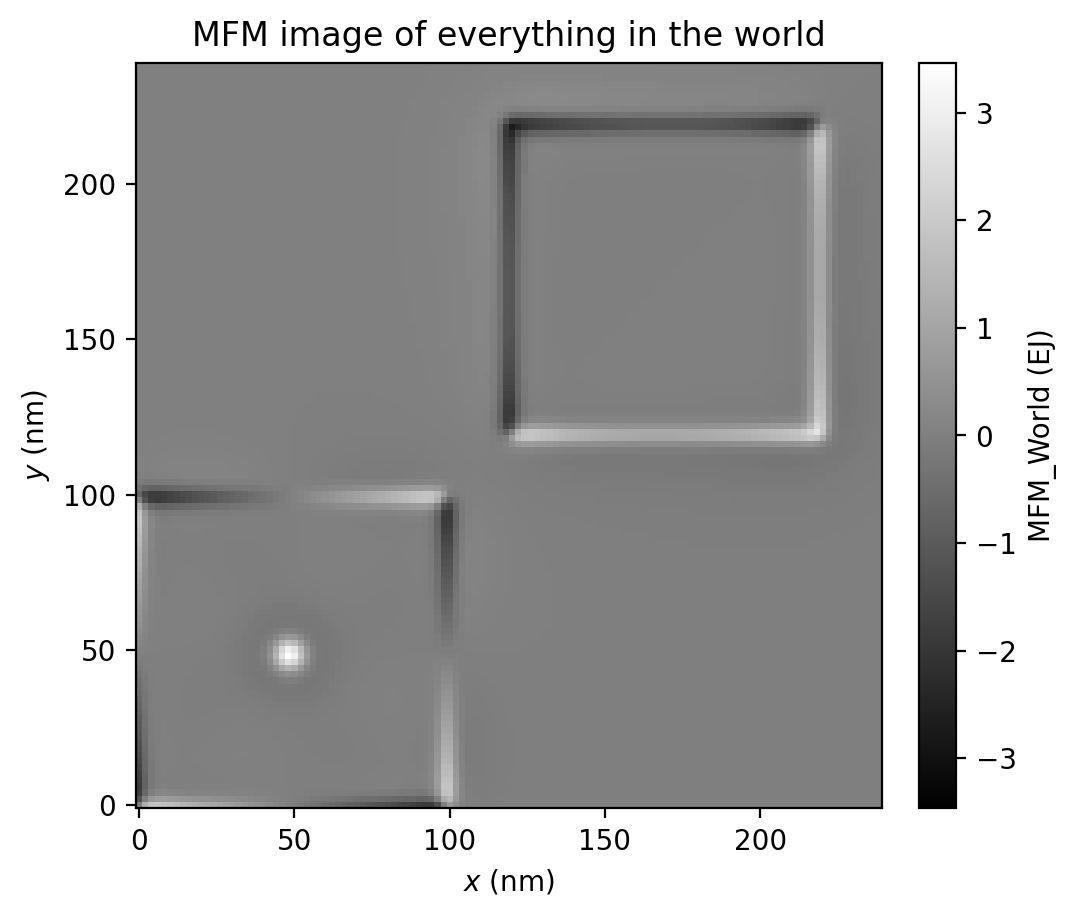

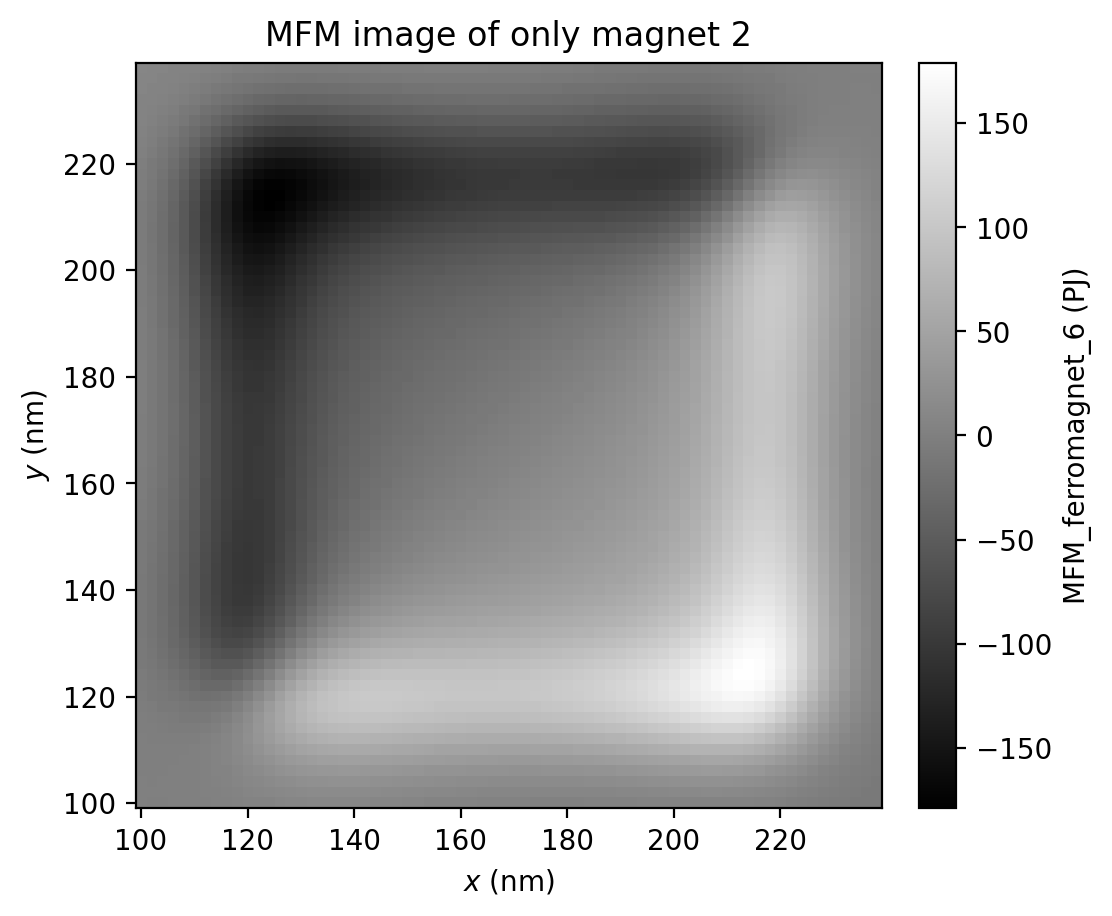

In [6]:
"""This script creates 2 magnets and visualizes them using magnetic force microscopy."""

import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet, Grid, World
from mumaxplus.util import MFM, plot_field, vortex

plt.rcParams["figure.dpi"] = 200

# SIMULATION PARAMETERS

msat = 566e3
aex = 2.48e-12
alpha = 1e-3

# WORLD SETUP

world = World(cellsize=(2e-9, 2e-9, 1e-9))

# MAGNET 1 INITIALIZATION

magnet1 = Ferromagnet(world, Grid((50, 50, 1)))
magnet1.magnetization = vortex(
    magnet1.center, diameter=4e-9, circulation=1, polarization=1
)
magnet1.msat = msat
magnet1.aex = aex
magnet1.alpha = alpha

# MAGNET 2 INITIALIZATION

magnet2 = Ferromagnet(world, Grid((50, 50, 1), origin=(60, 60, 0)))
magnet2.magnetization = (0.707, -0.707, 0)
magnet2.msat = msat
magnet2.aex = aex
magnet2.alpha = alpha

print("Minimizing magnets...")
world.minimize()

print("Creating MFM images...")

# GLOBAL MFM VISUALIZATION

grid_world = Grid((120, 120, 1))
mfm_world = MFM(world, grid_world)
mfm_world.lift = 5e-9

plot_field(
    mfm_world,
    imshow_kwargs={"cmap": "gray"},
    imshow_symmetric_clim=True,
    title="MFM image of everything in the world",
)

# LOCAL MFM VISUALIZATION

grid_magnet = Grid((70, 70, 1), origin=(50, 50, 0))
mfm_magnet = MFM(magnet2, grid_magnet)
mfm_magnet.lift = 20e-9

plot_field(
    mfm_magnet,
    imshow_kwargs={"cmap": "gray"},
    imshow_symmetric_clim=True,
    title="MFM image of only magnet 2",
)

plt.show()